downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Dataset shape: (400, 4096)
Image shape: (400, 64, 64)

PCA FROM SCRATCH
Components needed for 95% variance: 123
Variance retained by first 10 components: 66.06 %


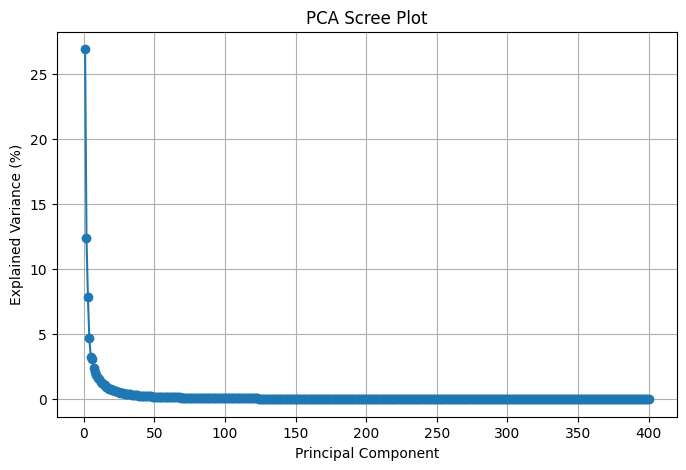

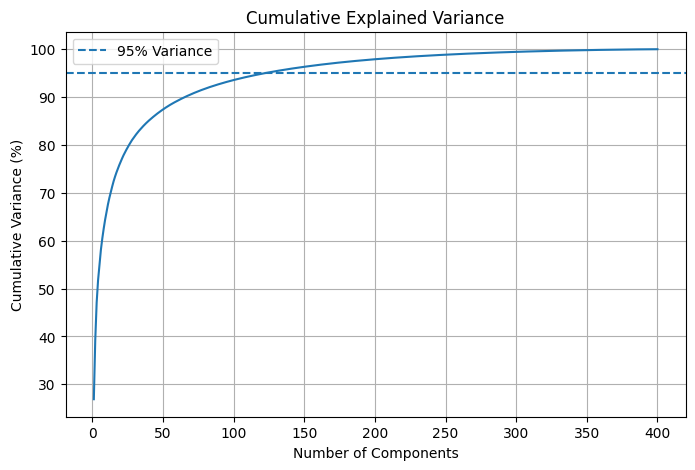


SCIKIT-LEARN PCA
First 5 explained variance ratios: [0.2688 0.1234 0.0784 0.0469 0.0325]

FROM SCRATCH PCA - First 5: [0.2688 0.1234 0.0784 0.0469 0.0325]


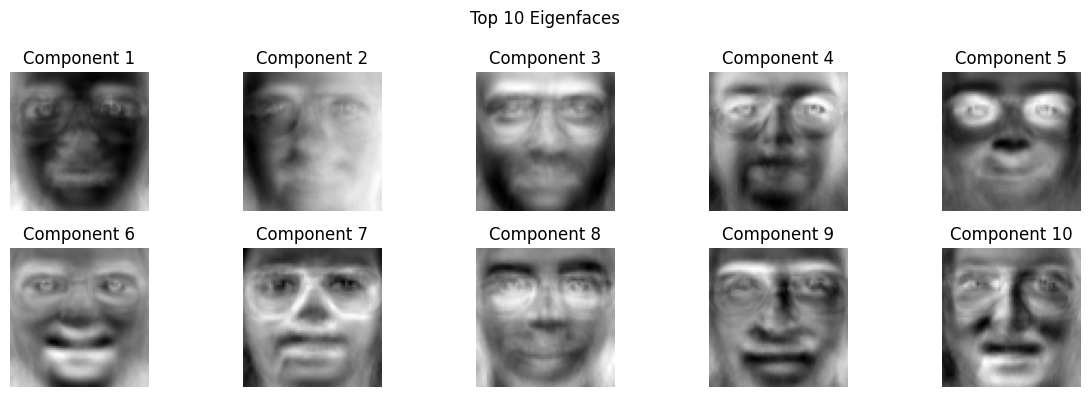

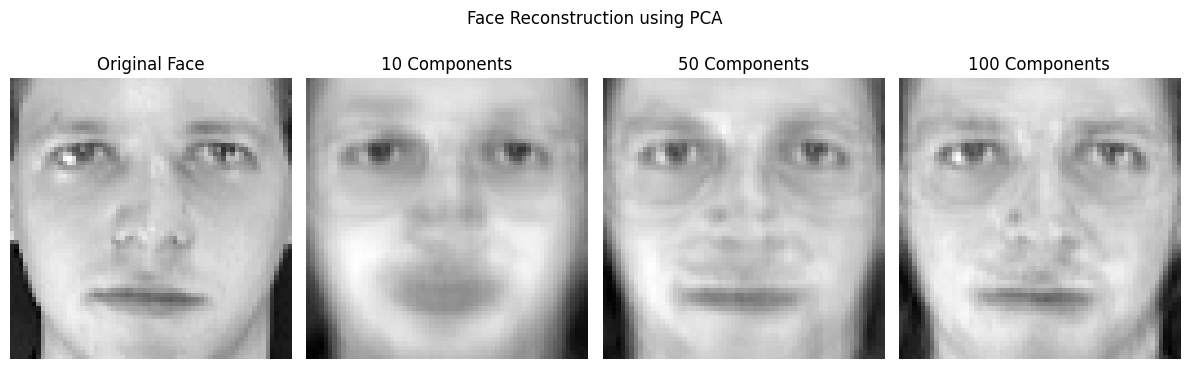


EXPERIMENT 19 COMPLETED SUCCESSFULLY!
PCA implemented from scratch.
PCA verified with Scikit-learn.
Eigenfaces and reconstructed faces displayed.


In [23]:
# EXPERIMENT 19: PCA AND EXPLAINED VARIANCE ANALYSIS

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. LOAD FACE DATASET

faces_data = fetch_olivetti_faces()

X = faces_data.data
images = faces_data.images

print("Dataset shape:", X.shape)
print("Image shape:", images.shape)

# 2. STANDARDIZE DATA

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# 3. PCA FROM SCRATCH USING COVARIANCE AND EIGEN-DECOMPOSITION

# Compute covariance matrix in sample space
# This is computationally efficient for high-dimensional face images

covariance_matrix = np.dot(
    X_scaled,
    X_scaled.T
) / (X_scaled.shape[1] - 1)

eigenvalues, eigenvectors = np.linalg.eigh(
    covariance_matrix
)

# Sort eigenvalues in descending order

indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[indices]
eigenvectors = eigenvectors[:, indices]

# Recover feature-space eigenvectors

components = np.dot(
    X_scaled.T,
    eigenvectors
)

components = components / np.sqrt(
    eigenvalues * (X_scaled.shape[1] - 1)
)

# 4. EXPLAINED VARIANCE

explained_variance_ratio = (
    eigenvalues / np.sum(eigenvalues)
)

cumulative_variance = np.cumsum(
    explained_variance_ratio
)

# Find components needed for 95% variance

n_components_95 = np.argmax(
    cumulative_variance >= 0.95
) + 1

print("\nPCA FROM SCRATCH")

print(
    "Components needed for 95% variance:",
    n_components_95
)

print(
    "Variance retained by first 10 components:",
    round(cumulative_variance[9] * 100, 2), "%"
)

# 5. SCREE PLOT

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(eigenvalues) + 1),
    explained_variance_ratio * 100,
    marker="o"
)

plt.title("PCA Scree Plot")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.grid(True)
plt.show()

# 6. CUMULATIVE EXPLAINED VARIANCE

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100
)

plt.axhline(
    y=95,
    linestyle="--",
    label="95% Variance"
)

plt.title("Cumulative Explained Variance")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance (%)")
plt.legend()
plt.grid(True)
plt.show()

# 7. VERIFY USING SCIKIT-LEARN PCA

sklearn_pca = PCA()

sklearn_pca.fit(X_scaled)

print("\nSCIKIT-LEARN PCA")

print(
    "First 5 explained variance ratios:",
    np.round(
        sklearn_pca.explained_variance_ratio_[:5],
        4
    )
)

print(
    "\nFROM SCRATCH PCA - First 5:",
    np.round(
        explained_variance_ratio[:5],
        4
    )
)

# 8. VISUALIZE TOP EIGENFACES

image_shape = images.shape[1:]

plt.figure(figsize=(12, 4))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    eigenface = components[:, i].reshape(image_shape)

    plt.imshow(eigenface, cmap="gray")

    plt.title(f"Component {i+1}")

    plt.axis("off")

plt.suptitle("Top 10 Eigenfaces")

plt.tight_layout()
plt.show()

# 9. RECONSTRUCTION WITH 10, 50 AND 100 COMPONENTS

sample_index = 0

original = X_scaled[sample_index]

component_counts = [10, 50, 100]

plt.figure(figsize=(12, 4))

# Original face

plt.subplot(1, 4, 1)

plt.imshow(
    images[sample_index],
    cmap="gray"
)

plt.title("Original Face")

plt.axis("off")

# PCA reconstruction

for i, n_components in enumerate(component_counts):

    pca = PCA(
        n_components=n_components
    )

    reduced_data = pca.fit_transform(X_scaled)

    reconstructed = pca.inverse_transform(
        reduced_data[sample_index].reshape(1, -1)
    )

    reconstructed = scaler.inverse_transform(
        reconstructed
    )

    reconstructed = reconstructed.reshape(image_shape)

    plt.subplot(1, 4, i + 2)

    plt.imshow(
        reconstructed,
        cmap="gray"
    )

    plt.title(
        f"{n_components} Components"
    )

    plt.axis("off")

plt.suptitle("Face Reconstruction using PCA")

plt.tight_layout()
plt.show()

# 10. FINAL OUTPUT

print("\nEXPERIMENT 19 COMPLETED SUCCESSFULLY!")
print("PCA implemented from scratch.")
print("PCA verified with Scikit-learn.")
print("Eigenfaces and reconstructed faces displayed.")